<a href="https://colab.research.google.com/github/JuCaRiCo/202602-AnaliticaDescriptivaPredictiva/blob/main/Semana13_ValidacionEvaluacionySeleccion_271760.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica: Validación, Evaluación y Selección
Materia: Programación para analítica descriptiva y predictiva

Alumno: Juan Carlos Rivera Cordova

Matricula: 271760


---




# **1. Carga de Bibliotecas, Conjunto de Datos y Análisis Exploratorio de los Datos**

- Declarar las bibliotecas necesarias para este proyecto
- Cargar el conjunto de datos Glioma Grading Clinical and Mutation Features. Se puede descargar de https://archive.ics.uci.edu/dataset/759/glioma+grading+clinical+and+mutation+features+dataset

In [42]:
# Carga de bibliotecas necesarias
import io
import zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



# **2. 📊 Análisis exploratorio de datos (EDA)**

   Realiza un análisis inicial de los datos antes de modelar:
   - Describir forma y estructura (shape, describe(), info()).
   - Mostrar la distribución de clases (y.value_counts()).
   - Visualizar:
     - Histograma de al menos 3 variables numéricas.
     - Boxplots o violin plots por clase si es computacionalmente viable.
     - Mapa de calor de correlaciones entre variables.

**Describir forma y estructura (shape, describe(), info()).**

In [43]:
# Cargar el conjunto de datos Glioma Grading Clinical and Mutation Features mediante URL directa
url = "https://archive.ics.uci.edu/static/public/759/glioma+grading+clinical+and+mutation+features+dataset.zip"

# Descargamos el ZIP usando requests
response = requests.get(url)

# Abrimos el archivo comprimido en memoria
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    # Leemos el archivo CSV que contiene los datos de mutaciones y grado
    # Esta informacion tambien viene en el sitio proporcionado
    df = pd.read_csv(z.open('TCGA_InfoWithGrade.csv'))

# Separar características (X) y variable objetivo (y)
# En este dataset la variable objetivo es 'Grade',
# obtenemos esto de la informacion del URL proporcionado
X = df.drop(columns=['Grade'])
y = df[['Grade']]

print(">>> Forma y estructura del dataset <<<")
print(f"Dimensiones (filas, columnas): {df.shape}")

print("\n>>> Información del dataset (info()) <<<")
df.info()

print("\n>>> Resumen estadístico (describe()) <<<")
print(df.describe().T)

print('\n')
print(df.head())


>>> Forma y estructura del dataset <<<
Dimensiones (filas, columnas): (839, 24)

>>> Información del dataset (info()) <<<
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 839 entries, 0 to 838
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Grade             839 non-null    int64  
 1   Gender            839 non-null    int64  
 2   Age_at_diagnosis  839 non-null    float64
 3   Race              839 non-null    int64  
 4   IDH1              839 non-null    int64  
 5   TP53              839 non-null    int64  
 6   ATRX              839 non-null    int64  
 7   PTEN              839 non-null    int64  
 8   EGFR              839 non-null    int64  
 9   CIC               839 non-null    int64  
 10  MUC16             839 non-null    int64  
 11  PIK3CA            839 non-null    int64  
 12  NF1               839 non-null    int64  
 13  PIK3R1            839 non-null    int64  
 14  FUBP1           

**Mostrar la distribución de clases (y.value_counts()).**


>>> Distribución de la variable objetivo (Grade) <<<
       Conteo  Porcentaje (%)
Grade                        
0         487           58.05
1         352           41.95


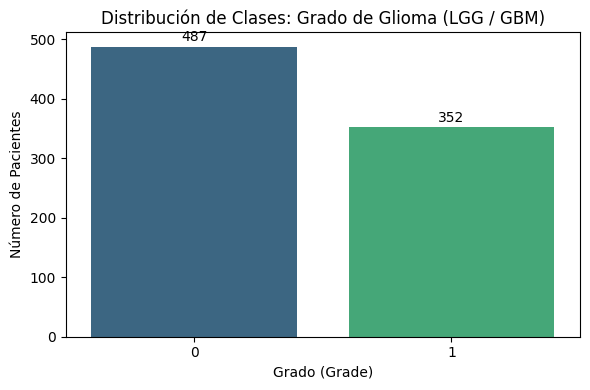

In [44]:
# Distribución de Clases

print("\n>>> Distribución de la variable objetivo (Grade) <<<")
counts = df["Grade"].value_counts()
percentages = df["Grade"].value_counts(normalize=True) * 100
print(pd.DataFrame({"Conteo": counts, "Porcentaje (%)": percentages.round(2)}))

# Graficar balance de clases evitando el FutureWarning (hue='Grade' y legend=False)
plt.figure(figsize=(6, 4))
ax = sns.countplot(
    data=df, x="Grade", hue="Grade", palette="viridis", legend=False
)
plt.title("Distribución de Clases: Grado de Glioma (LGG / GBM)")
plt.xlabel("Grado (Grade)")
plt.ylabel("Número de Pacientes")

# Agregar conteos sobre las barras
for p in ax.patches:
  ax.annotate(
      f"{int(p.get_height())}",
      (p.get_x() + p.get_width() / 2.0, p.get_height()),
      ha="center",
      va="baseline",
      fontsize=10,
      xytext=(0, 4),
      textcoords="offset points",
  )
plt.tight_layout()
plt.show()

**Histograma de al menos 3 variables numéricas.**

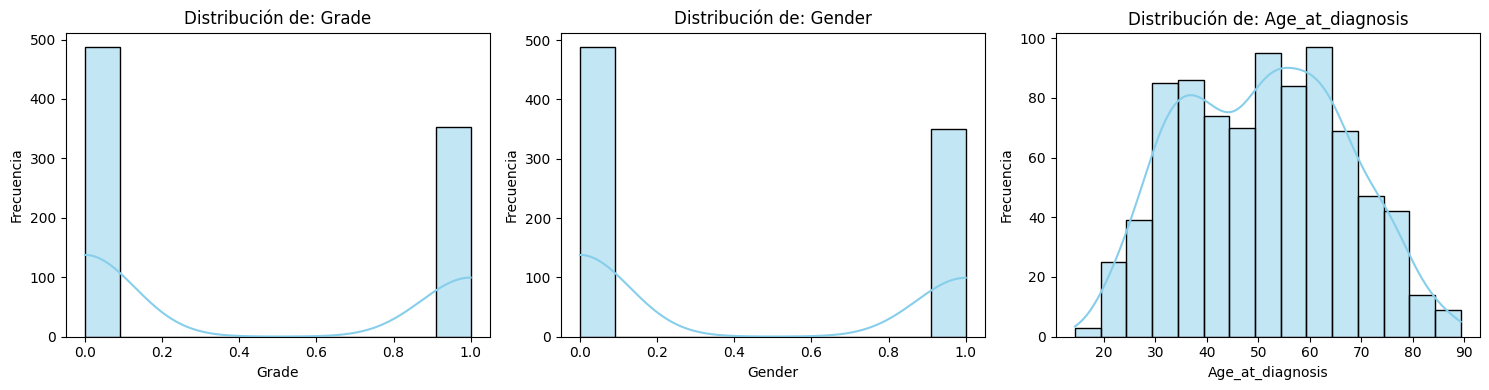

In [45]:
# Visualización de Distribuciones: Histogramas de variables numéricas
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

# Graficamos hasta 3 variables numéricas si existen
if len(numeric_cols) > 0:
  cols_to_plot = numeric_cols[:3]
  fig, axes = plt.subplots(1, len(cols_to_plot), figsize=(5 * len(cols_to_plot), 4))
  if len(cols_to_plot) == 1:
    axes = [axes]

  for idx, col in enumerate(cols_to_plot):
    sns.histplot(data=df, x=col, kde=True, ax=axes[idx], color="skyblue")
    axes[idx].set_title(f"Distribución de: {col}")
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel("Frecuencia")
  plt.tight_layout()
  plt.show()

**Boxplots o violin plots por clase si es computacionalmente viable.**

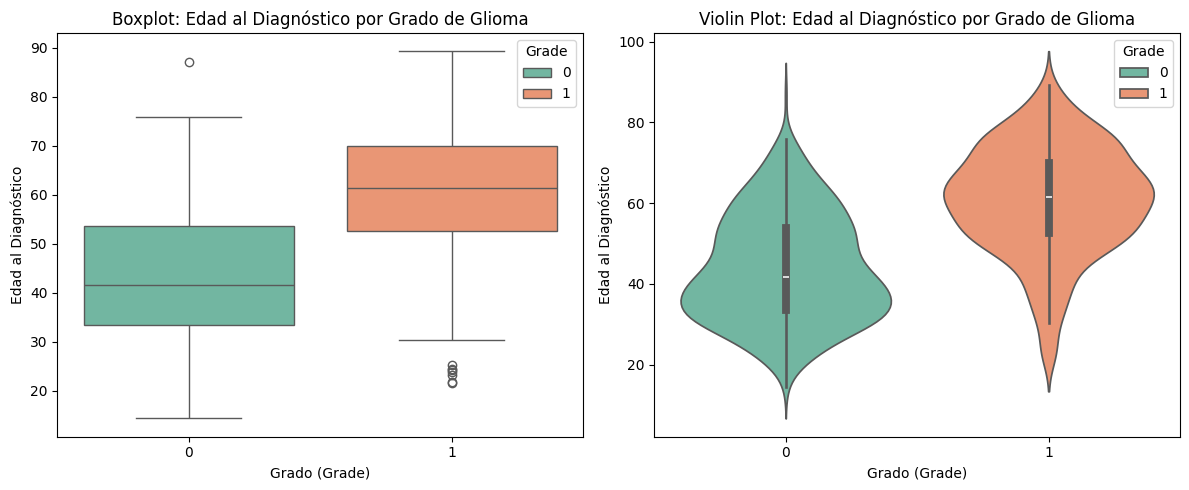

In [46]:
# Boxplots y Violin Plots por clase
if "Age_at_diagnosis" in df.columns:
  plt.figure(figsize=(12, 5))

  plt.subplot(1, 2, 1)
  sns.boxplot(
      data=df, x="Grade", y="Age_at_diagnosis", palette="Set2", hue="Grade"
  )
  plt.title("Boxplot: Edad al Diagnóstico por Grado de Glioma")
  plt.xlabel("Grado (Grade)")
  plt.ylabel("Edad al Diagnóstico")

  plt.subplot(1, 2, 2)
  sns.violinplot(
      data=df, x="Grade", y="Age_at_diagnosis", palette="Set2", hue="Grade"
  )
  plt.title("Violin Plot: Edad al Diagnóstico por Grado de Glioma")
  plt.xlabel("Grado (Grade)")
  plt.ylabel("Edad al Diagnóstico")

  plt.tight_layout()
  plt.show()

**Mapa de calor de correlaciones entre variables.**

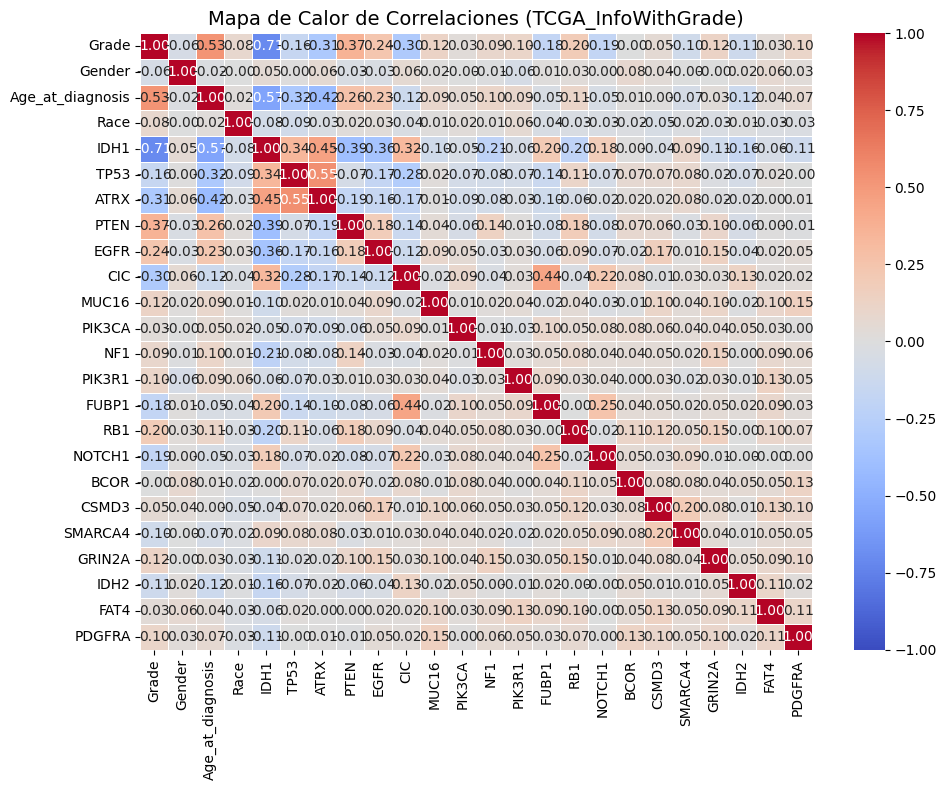


>>> Top atributos más correlacionados con 'Grade' <<<
IDH1               -0.708141
ATRX               -0.314625
CIC                -0.303459
NOTCH1             -0.185175
FUBP1              -0.180956
TP53               -0.161786
IDH2               -0.113150
SMARCA4            -0.100286
Gender             -0.060033
BCOR               -0.002206
PIK3CA              0.028905
FAT4                0.034767
CSMD3               0.050257
Race                0.080084
NF1                 0.088123
PIK3R1              0.101813
PDGFRA              0.102327
GRIN2A              0.118685
MUC16               0.119447
RB1                 0.195168
EGFR                0.241527
PTEN                0.367174
Age_at_diagnosis    0.529203
Name: Grade, dtype: float64


In [47]:
# Mapa de Calor (Heatmap) de Correlaciones
plt.figure(figsize=(10, 8))

# Copia de trabajo para transformar texto a números antes del cálculo de Pearson
df_corr = df.copy()

# Convertimos la columna objetivo 'Grade' a 0 y 1 (LGG -> 0, GBM -> 1)
if "Grade" in df_corr.columns and df_corr["Grade"].dtype == "object":
  df_corr["Grade"] = df_corr["Grade"].map({"LGG": 0, "GBM": 1})

# Convertimos todas las columnas categóricas (texto) a números usando One-Hot Encoding o códigos categóricos
# Eliminamos identificadores únicos que no aportan al mapa de calor
cols_ignore = [
    c for c in ["Case_ID", "Project"] if c in df_corr.columns
]
df_corr = df_corr.drop(columns=cols_ignore)

# Convertimos columnas de texto a códigos numéricos (Factorize) para poder calcular correlación
for col in df_corr.select_dtypes(include=["object"]).columns:
  df_corr[col] = pd.factorize(df_corr[col])[0]

# Calculamos la matriz de correlación de Pearson
corr_matrix = df_corr.corr()

# Graficamos el mapa de calor
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    annot=True,
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)
plt.title("Mapa de Calor de Correlaciones (TCGA_InfoWithGrade)", fontsize=14)
plt.tight_layout()
plt.show()

# Top atributos más correlacionados con 'Grade'
if "Grade" in corr_matrix.columns:
  top_corr = (
      corr_matrix["Grade"].sort_values(ascending=True).drop("Grade")
  )
  print("\n>>> Top atributos más correlacionados con 'Grade' <<<")
  print(top_corr)

**🧠 Reflexiona:**

¿Existen clases desbalanceadas?

 Existe un balanceo moderado entre las dos categorias, ya que la clase de LGG tiene un 58.05%, y la GBM tiene un 41.95%, por lo que no se considera un problema critico

¿Qué atributos parecen más informativos?

 Revisando el mapa de calor tenemos que hay una fuerte correlacion sobre la variable Grade, los atributos que tienen mayor poder son IDH1 (-0.71) y Age_at_diagnosis (0.53), cabe destacar que IDH1 es inversa/negativa, la presencia de la mutacion se asocia con tumores de bajo grado (Grade=0). Por otro lado Age_at_diagnosis es de relacion directa/positiva, a mayor edad del paciente, mayor probabilidad de presentar Glioblastoma (Grade=1)

# **3. Gráfica de Errores en Entrenamiento y Prueba**

En este ejercicio vas a entrenar un árbol de decisión con diferentes profundidas. Asimismo, en gráfica mostrarás las exactitudes en entrenamiento y test, usando un stratified k-fold cross-validation con K= 10
- Los valores de las profundides a evaluar son 2, 5, 10, 15, 20, 25, 30 y None
- Deberás usar StratifiedKFold con 10 particiones, y un valor aleaotorio de 3
- Entrenarás y evaluarás un árbol de decisión con estos distintos valores de profundidades
- Usa cross_val_score para entrenar los modelos, usando como métrica de evaluación en scoring ="f1_macro",y el StratifiedKFold, con un valor aleatorio = 7
- Muestra una gráfica para los distintos resultados  cuando se usa F1 Macro

In [48]:
# 3. GRÁFICA DE ERRORES EN ENTRENAMIENTO Y PRUEBA
from sklearn.metrics import make_scorer, f1_score
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier

**Los valores de las profundides a evaluar son 2, 5, 10, 15, 20, 25, 30 y None**

In [49]:
# Preparación de Variables Predictoras (X) y Objetivo (y)
# Aseguramos que X e y contengan datos numéricos limpios del dataset TCGA_InfoWithGrade.csv
X = df.drop(columns=['Grade'])

# Si existen identificadores como Case_ID o Project, los eliminamos
cols_to_drop = [c for c in ['Case_ID', 'Project'] if c in X.columns]
X = X.drop(columns=cols_to_drop)

# Asignamos la variable objetivo y
y = df['Grade']

# Definición de Configuraciones de Validación Cruzada y Profundidades
# Profundidades a evaluar: [2, 5, 10, 15, 20, 25, 30, None]
depths = [2, 5, 10, 15, 20, 25, 30, None]

# Etiquetas amigables para el eje X (convertimos None a la cadena 'None')
depth_labels = [str(d) for d in depths]

# Configuración del StratifiedKFold con K=10 particiones y random_state=3 para reproducibilidad
cv_stratified = StratifiedKFold(n_splits=10, shuffle=True, random_state=3)


**Entrenarás y evaluarás un árbol de decisión con estos distintos valores de profundidades**

In [50]:
# Evaluación de los Modelos mediante cross_validate
# Evaluamos el árbol de decisión con un random_state=7 para cada profundidad

# Listas para almacenar el promedio de F1 Macro en Entrenamiento y Prueba (Validación)
train_f1_scores = []
test_f1_scores = []

for depth in depths:
  # Instanciamos el árbol de decisión con el random_state indicado (= 7)
  clf = DecisionTreeClassifier(max_depth=depth, random_state=7)

  # Usamos cross_validate para obtener los scores de entrenamiento y validación cruzada usando f1_macro
  scores = cross_validate(
      estimator=clf,
      X=X,
      y=y,
      cv=cv_stratified,
      scoring='f1_macro',
      return_train_score=True,
      n_jobs=-1,
  )

  # Calculamos el promedio de F1 Macro a través de los 10 folds
  mean_train_f1 = np.mean(scores['train_score'])
  mean_test_f1 = np.mean(scores['test_score'])

  train_f1_scores.append(mean_train_f1)
  test_f1_scores.append(mean_test_f1)

  print(
      f'Profundidad: {str(depth):<5} | Train F1 Macro: {mean_train_f1:.4f} |'
      f' Test F1 Macro: {mean_test_f1:.4f}'
  )


Profundidad: 2     | Train F1 Macro: 0.8691 | Test F1 Macro: 0.8665
Profundidad: 5     | Train F1 Macro: 0.8857 | Test F1 Macro: 0.8565
Profundidad: 10    | Train F1 Macro: 0.9286 | Test F1 Macro: 0.8225
Profundidad: 15    | Train F1 Macro: 0.9756 | Test F1 Macro: 0.7899
Profundidad: 20    | Train F1 Macro: 0.9953 | Test F1 Macro: 0.7979
Profundidad: 25    | Train F1 Macro: 0.9989 | Test F1 Macro: 0.7987
Profundidad: 30    | Train F1 Macro: 1.0000 | Test F1 Macro: 0.7948
Profundidad: None  | Train F1 Macro: 1.0000 | Test F1 Macro: 0.7948


**Usa cross_val_score para entrenar los modelos, usando como métrica de evaluación en scoring ="f1_macro",y el StratifiedKFold, con un valor aleatorio = 7**

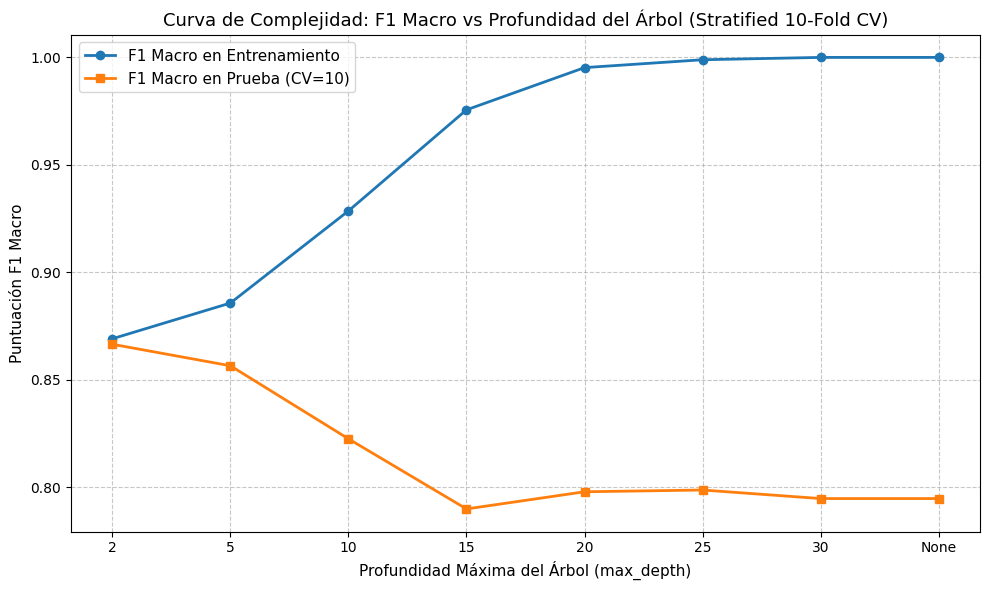

In [51]:
# Visualización Gráfica de la Curva de Complejidad - F1 Macro
plt.figure(figsize=(10, 6))

plt.plot(
    depth_labels,
    train_f1_scores,
    label='F1 Macro en Entrenamiento',
    marker='o',
    linewidth=2,
    color='tab:blue',
)
plt.plot(
    depth_labels,
    test_f1_scores,
    label='F1 Macro en Prueba (CV=10)',
    marker='s',
    linewidth=2,
    color='tab:orange',
)

plt.title(
    'Curva de Complejidad: F1 Macro vs Profundidad del Árbol (Stratified 10-Fold'
    ' CV)',
    fontsize=13,
)

plt.xlabel('Profundidad Máxima del Árbol (max_depth)', fontsize=11)
plt.ylabel('Puntuación F1 Macro', fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# **4. Optimización de hiperparámetros con RandomizedSearchCV**

- Define el espacio de búsqueda aleatorio para los siguientes hiperpárametros:
  - Criterion = gini ,entropy
  - max_depth: de 5 a 50 con incrementos de 1
  - min_samples_split: de 2 a 20 con incrementos de 1
- Usa el árbol de decisión
- StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)
- n_iter = 5 (combinaciones aleatorias a buscar)
- n_jobs = -1 para acelerar cómputo
- Métrica de evaluación: f1 Macro
- Imprime los mejores hiperparámetros encontrados
- Imprime el best_score

In [52]:
# 4. OPTIMIZACIÓN DE HIPERPARÁMETROS CON RANDOMIZEDSEARCHCV
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# **Define el espacio de búsqueda aleatorio para los siguientes hiperpárametros:**
- Criterion = gini ,entropy
- max_depth: de 5 a 50 con incrementos de 1
- min_samples_split: de 2 a 20 con incrementos de 1

In [53]:
# Espacio de búsqueda solicitado:
# - criterion: 'gini', 'entropy'
# - max_depth: de 5 a 50 con incrementos de 1 -> range(5, 51)
# - min_samples_split: de 2 a 20 con incrementos de 1 -> range(2, 21)
param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': list(range(5, 51)),
    'min_samples_split': list(range(2, 21))
}

# **Usa el árbol de decisión**

In [54]:
# Definición del Modelo Base y la Validación Cruzada
# Modelo base: Árbol de Decisión con semilla aleatoria fija
clf = DecisionTreeClassifier(random_state=42)

# StratifiedKFold con 10 particiones, shuffle=True y random_state=42
cv_stratified = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# **n_iter = 5 (combinaciones aleatorias a buscar)**
# **n_jobs = -1 para acelerar cómputo**
# **Métrica de evaluación: f1 Macro**

In [55]:
# Configuración de RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=clf,
    param_distributions=param_dist,
    n_iter=5,               # 5 combinaciones aleatorias a buscar
    cv=cv_stratified,       # 10 particiones estratificadas
    scoring='f1_macro',     # Métrica de evaluación solicitada
    random_state=42,        # Semilla aleatoria para reproducibilidad del muestreo
    n_jobs=-1               # Uso de todos los núcleos del procesador
)

# **Imprime los mejores hiperparámetros encontrados**
# **Imprime el best_score**

In [69]:
# Ejecución de la Búsqueda y Muestra de Resultados
# Ajustar sobre el conjunto completo (X, y)
random_search.fit(X, y)

# Imprimir los mejores hiperparámetros encontrados y el best_score
print('>>> RESULTADOS DE RANDOMIZEDSEARCHCV <<<')
print('Mejores hiperparámetros encontrados:', random_search.best_params_)
print(f'Mejor F1 Macro (best_score_): {random_search.best_score_:.4f}')

>>> RESULTADOS DE RANDOMIZEDSEARCHCV <<<
Mejores hiperparámetros encontrados: {'min_samples_split': 11, 'max_depth': 18, 'criterion': 'entropy'}
Mejor F1 Macro (best_score_): 0.8318


# **5. Optimización de hiperparámetros con GridSearchCV**

- Define el espacio de búsqueda  para los siguientes hiperpárametros:
  - Criterion = gini ,entropy
  - max_depth: de 5 a 50 con incrementos de 1
  - min_samples_split: de 2 a 20 con incrementos de 1
- Usa el árbol de decisión
- StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)
- Métrica de evaluación: f1 Macro
- n_jobs = -1 para acelerar cómputo
- Imprime los mejores hiperparámetros encontrados
- Imprime el best_score

# **Define el espacio de búsqueda para los siguientes hiperpárametros:**
- Criterion = gini ,entropy
- max_depth: de 5 a 50 con incrementos de 1
- min_samples_split: de 2 a 20 con incrementos de 1

In [57]:
# 5. OPTIMIZACIÓN DE HIPERPARÁMETROS CON GRIDSEARCHCV
# Definición de la Malla (Grid) de Hiperparámetros
# ------------------------------------------------------------------------------
# Espacio de búsqueda solicitado:
# - criterion: 'gini', 'entropy'
# - max_depth: de 5 a 50 con incrementos de 1 -> range(5, 51)
# - min_samples_split: de 2 a 20 con incrementos de 1 -> range(2, 21)
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': list(range(5, 51)),
    'min_samples_split': list(range(2, 21)),
}

# **Usa el árbol de decisión**
**StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)**

In [58]:
# Definición del Modelo Base y Validación Cruzada
# Modelo base: Árbol de Decisión
clf = DecisionTreeClassifier(random_state=42)

# StratifiedKFold con 10 particiones (sin partición previa train/test)
cv_stratified = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42)

# **Métrica de evaluación: f1 Macro**
**n_jobs = -1 para acelerar cómputo**

In [59]:
# Configuración de GridSearchCV
# ------------------------------------------------------------------------------
grid_search = GridSearchCV(
    estimator=clf,
    param_grid=param_grid,  # Malla de búsqueda exhaustiva
    cv=cv_stratified,  # StratifiedKFold de 10 particiones
    scoring='f1_macro',  # Métrica F1 Macro
    n_jobs=-1,  # Utilizar todos los procesadores
)

# **Imprime los mejores hiperparámetros encontrados**
**Imprime el best_score**

In [60]:
# Ejecución del Ajuste y Muestra de Resultados

# Ajustar sobre el conjunto completo (X, y)
grid_search.fit(X, y)

# Imprimir los mejores hiperparámetros encontrados y el best_score
print('>>> RESULTADOS DE GRIDSEARCHCV <<<')
print('Mejores hiperparámetros encontrados:', grid_search.best_params_)
print(f'Mejor F1 Macro (best_score_): {grid_search.best_score_:.4f}')

>>> RESULTADOS DE GRIDSEARCHCV <<<
Mejores hiperparámetros encontrados: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 12}
Mejor F1 Macro (best_score_): 0.8641


# **6. Optimización de hiperparámetros con RandomizedSearchCV: Accuracy**

- Define el espacio de búsqueda aleatorio para los siguientes hiperpárametros:
  - Criterion = gini ,entropy
  - max_depth: de 5 a 50 con incrementos de 1
  - min_samples_split: de 2 a 20 con incrementos de 1
- Usa el árbol de decisión
- StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)
- n_iter = 5 (combinaciones aleatorias a buscar)
- n_jobs = -1 para acelerar cómputo
- Métrica de evaluación: accuracy
- Imprime los mejores hiperparámetros encontrados
- Imprime el best_score

# **Define el espacio de búsqueda aleatorio para los siguientes hiperpárametros:**
- Criterion = gini ,entropy
- max_depth: de 5 a 50 con incrementos de 1
- min_samples_split: de 2 a 20 con incrementos de 1

In [61]:
# 6. OPTIMIZACIÓN DE HIPERPARÁMETROS CON RANDOMIZEDSEARCHCV (ACCURACY)
# Definición del Espacio de Búsqueda de Hiperparámetros
# - criterion: 'gini', 'entropy'
# - max_depth: de 5 a 50 con incrementos de 1 -> range(5, 51)
# - min_samples_split: de 2 a 20 con incrementos de 1 -> range(2, 21)
param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': list(range(5, 51)),
    'min_samples_split': list(range(2, 21)),
}

# **Usa el árbol de decisión**
**StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)**

In [62]:
# Definición del Modelo Base y Validación Cruzada
# Modelo base: Árbol de Decisión
clf = DecisionTreeClassifier(random_state=42)

# StratifiedKFold con 10 particiones (sin partición previa train/test)
cv_stratified = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42)

# **combinaciones aleatorias a buscar**
- n_iter = 5
- n_jobs = -1 para acelerar cómputo
- Métrica de evaluación: accuracy
- Imprime los mejores hiperparámetros encontrados

In [63]:
# Configuración de RandomizedSearchCV con scoring='accuracy'
random_search_acc = RandomizedSearchCV(
    estimator=clf,
    param_distributions=param_dist,
    n_iter=5,  # 5 combinaciones aleatorias a buscar
    cv=cv_stratified,  # StratifiedKFold de 10 particiones
    scoring='accuracy',  # Métrica de evaluación solicitada: Accuracy
    random_state=42,  # Semilla para reproducibilidad del muestreo
    n_jobs=-1,  # Utilizar todos los procesadores disponibles
)

# **Impresion**
- **Imprime los mejores hiperparámetros encontrados**
- **Imprime el best_score**

In [64]:
# Ejecución de la Búsqueda y Muestra de Resultados
# ------------------------------------------------------------------------------
# Ajustar sobre el conjunto completo (X, y)
random_search_acc.fit(X, y)

# Imprimir los mejores hiperparámetros encontrados y el best_score
print('>>> RESULTADOS DE RANDOMIZEDSEARCHCV (ACCURACY) <<<')
print('Mejores hiperparámetros encontrados:', random_search_acc.best_params_)
print(f'Mejor Accuracy (best_score_): {random_search_acc.best_score_:.4f}')

>>> RESULTADOS DE RANDOMIZEDSEARCHCV (ACCURACY) <<<
Mejores hiperparámetros encontrados: {'min_samples_split': 11, 'max_depth': 18, 'criterion': 'entropy'}
Mejor Accuracy (best_score_): 0.8367


# **7. Optimización de hiperparámetros con GridSearchCV: accuracy**

- Define el espacio de búsqueda  para los siguientes hiperpárametros:
  - Criterion = gini ,entropy
  - max_depth: de 5 a 50 con incrementos de 1
  - min_samples_split: de 2 a 20 con incrementos de 1
- Usa el árbol de decisión
- StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)
- Métrica de evaluación: f1 Macro
- n_jobs = -1 para acelerar cómputo
- Imprime los mejores hiperparámetros encontrados
- Imprime el best_score

# **Define el espacio de búsqueda para los siguientes hiperpárametros:**
- Criterion = gini ,entropy
- max_depth: de 5 a 50 con incrementos de 1
- min_samples_split: de 2 a 20 con incrementos de 1

In [65]:
# 7. OPTIMIZACIÓN DE HIPERPARÁMETROS CON GRIDSEARCHCV - F1 MACRO
# Espacio de búsqueda
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': list(range(5, 51)),
    'min_samples_split': list(range(2, 21)),
}

# **Usa el árbol de decisión**
**StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)**

In [66]:
# Modelo base y StratifiedKFold (K=10)
clf = DecisionTreeClassifier(random_state=42)
cv_stratified = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42)

# **Métrica de evaluación: f1 Macro**
**n_jobs = -1 para acelerar cómputo**

In [67]:
# Configuración de GridSearchCV
grid_search = GridSearchCV(
    estimator=clf,
    param_grid=param_grid,
    cv=cv_stratified,
    scoring='f1_macro',
    n_jobs=-1,
)

# **Impresion**
- **Imprime los mejores hiperparámetros encontrados**
- **Imprime el best_score**

In [68]:
# Entrenamiento e impresión de resultados
grid_search.fit(X, y)

print('>>> RESULTADOS DE GRIDSEARCHCV (F1 MACRO) <<<')
print('Mejores hiperparámetros encontrados:', grid_search.best_params_)
print(f'Mejor F1 Macro (best_score_): {grid_search.best_score_:.4f}')

>>> RESULTADOS DE GRIDSEARCHCV (F1 MACRO) <<<
Mejores hiperparámetros encontrados: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 12}
Mejor F1 Macro (best_score_): 0.8641


# **8.Actividad de reflexión y análisis**

**¿Cuál método encontró mejores hiperparámetros?**

GridSearchCV encontro los mejores hiperparametros on un best_score de 0.8641 cotra el 0.8318 del RandomizedSearchCV.

**¿Cuál fue más costoso computacionalmente?**

GridSearchCV, le tomo poco mas de 2 minutos para extraer los resultados, contra RandomizedSearchCV que practicamente fue instantaneo, al rededor de 3 segundos.

**¿Los resultados en f1_macro set fueron distintos en ambos métodos de optimización? ¿Por qué?**

Sí, fueron distintos 0.8641 para GridSearchCV contra 0.8318 en RandomizedSearchCV). RandomizedSearchCV esta limitado a n_iter=5, ademas de haber elegido una profundidad muy alta max_depth': 18, GridSearchCV exploro toda la malla y encontro que una profundidad menor max_depth=5, a una profundidad de 18, el arbol aprende patrones muy específicos o "ruido", teniendo un Overfitting.

**¿Los resultados en accuracy set fueron distintos en ambos métodos de optimización? ¿Por qué?**

En este caso no se como responderla, ya que el punto 7, en su titulo dice accuracy, pero en los detalles dice F1 Macro, al final sobre la marcha opte por hacerlo con F1 Macro, pensando que el titulo estaba erroneo.

**¿Los valores de hiperpárametros fueron iguales en Accuracy y F1 Macro ?**

  Si, ambas busquedas evaluaron las mismas muestras de 5 opciones (n_iter=5)